# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Ayu Rahma Adibrata
- **Email:** ds185b6x0301@student.devacademy.id
- **ID Dicoding:** DS185B6X0301

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola rata-rata jumlah penyewaan sepeda (`cnt`) berdasarkan jam dalam sehari dan status hari (hari kerja atau hari nonkerja) selama periode 2011–2012, serta pada jam berapa puncak permintaan terjadi pada masing-masing jenis hari untuk membantu pengaturan ketersediaan sepeda?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda (`cnt`) pada setiap kategori kondisi cuaca (`weathersit` 1–4) selama periode 2011–2012, dan kategori cuaca mana yang menunjukkan tingkat permintaan paling rendah sebagai bahan pertimbangan penyesuaian operasional?
- ...

## Import Semua Packages/Library yang Digunakan

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Agar hasil angka dan tabel lebih mudah dibaca.
pd.options.display.float_format = "{:,.2f}".format

## Data Wrangling

### Gathering Data

#### Load df hour.csv

In [ ]:
# Mencari dataset pada beberapa lokasi umum:
# - data/hour.csv: jika notebook dijalankan dari folder utama proyek
# - hour.csv atau /content/hour.csv: jika file diunggah langsung ke Google Colab

candidate_paths = [
    Path("data/hour.csv"),
    Path("hour.csv"),
    Path("../data/hour.csv"),
    Path("/content/hour.csv")
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File hour.csv belum ditemukan. Unggah hour.csv ke Google Colab "
        "atau letakkan file pada folder data/ di samping notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Dataset dibaca dari: {DATA_PATH}")
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")
display(df.head())

Dataset dibaca dari: hour.csv
Jumlah baris: 17,379
Jumlah kolom: 17


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


**Insight:** (Opsional)
- Dataset `hour.csv` berhasil dimuat dengan 17.379 baris dan 17 kolom.
- Data mencakup catatan penyewaan per jam pada periode 1 Januari 2011 sampai 31 Desember 2012.

### Assessing Data

#### Identifying data quality problems

In [ ]:
# Pemeriksaan struktur dan kualitas data
print("Informasi umum dataset:")
df.info()

print("\nJumlah missing value per kolom:")
display(df.isna().sum().to_frame("missing_value"))

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

# Pemeriksaan rentang nilai untuk kolom yang memiliki kode/rentang yang diketahui.
valid_ranges = {
    "season": (1, 4),
    "yr": (0, 1),
    "mnth": (1, 12),
    "hr": (0, 23),
    "holiday": (0, 1),
    "weekday": (0, 6),
    "workingday": (0, 1),
    "weathersit": (1, 4),
    "temp": (0, 1),
    "atemp": (0, 1),
    "hum": (0, 1),
    "windspeed": (0, 1)
}

range_check = []
for column, (minimum, maximum) in valid_ranges.items():
    invalid_count = ((df[column] < minimum) | (df[column] > maximum)).sum()
    range_check.append({
        "kolom": column,
        "nilai_minimum": df[column].min(),
        "nilai_maksimum": df[column].max(),
        "jumlah_nilai_di_luar_rentang": int(invalid_count)
    })

print("\nPemeriksaan rentang nilai:")
display(pd.DataFrame(range_check))

# Pemeriksaan konsistensi jumlah penyewaan.
count_mismatch = (df["cnt"] != df["casual"] + df["registered"]).sum()
negative_rentals = (df[["casual", "registered", "cnt"]] < 0).sum()

print(f"\nJumlah baris dengan cnt != casual + registered: {count_mismatch}")
print("Jumlah nilai penyewaan negatif:")
display(negative_rentals.to_frame("jumlah"))

# Pemeriksaan kandidat outlier pada jumlah penyewaan menggunakan metode IQR.
q1 = df["cnt"].quantile(0.25)
q3 = df["cnt"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (df["cnt"] < lower_bound) | (df["cnt"] > upper_bound)

print("\nPemeriksaan kandidat outlier kolom cnt:")
print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Batas bawah: {lower_bound:.2f} | Batas atas: {upper_bound:.2f}")
print(f"Jumlah kandidat outlier: {outlier_mask.sum():,}")

print("\nJumlah observasi berdasarkan kondisi cuaca:")
display(df["weathersit"].value_counts().sort_index().rename_axis("weathersit").to_frame("jumlah_observasi"))

Informasi umum dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Jumlah missing value per

,missing_value
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Jumlah baris duplikat:
0

Pemeriksaan rentang nilai:


,kolom,nilai_minimum,nilai_maksimum,jumlah_nilai_di_luar_rentang
0,season,1.00,4.00,0
1,yr,0.00,1.00,0
2,mnth,1.00,12.00,0
3,hr,0.00,23.00,0
4,holiday,0.00,1.00,0
5,weekday,0.00,6.00,0
6,workingday,0.00,1.00,0
7,weathersit,1.00,4.00,0
8,temp,0.02,1.00,0
9,atemp,0.00,1.00,0



Jumlah baris dengan cnt != casual + registered: 0
Jumlah nilai penyewaan negatif:


,jumlah
casual,0
registered,0
cnt,0



Pemeriksaan kandidat outlier kolom cnt:
Q1: 40.00 | Q3: 281.00 | IQR: 241.00
Batas bawah: -321.50 | Batas atas: 642.50
Jumlah kandidat outlier: 505

Jumlah observasi berdasarkan kondisi cuaca:


,jumlah_observasi
weathersit,
1,11413
2,4544
3,1419
4,3


**Steps to Take:**
- Mengubah kolom `dteday` dari tipe `object` menjadi `datetime` agar dapat digunakan dalam analisis waktu.
- Memeriksa kandidat outlier pada `cnt` menggunakan metode IQR. Nilai tersebut tidak langsung dihapus; validitasnya diperiksa melalui konsistensi `cnt = casual + registered` dan pemeriksaan nilai negatif.
- Menambahkan label yang mudah dibaca untuk kode hari kerja dan kondisi cuaca agar hasil analisis lebih mudah diinterpretasikan.

**Insight:** (Opsional)
- Tidak ditemukan missing value maupun baris duplikat pada dataset.
- Ditemukan dua hal yang perlu ditangani: tipe data tanggal yang belum sesuai dan 505 kandidat outlier pada jumlah penyewaan berdasarkan metode IQR. Kategori cuaca 4 juga hanya memiliki 3 observasi sehingga interpretasinya perlu dibatasi.

### Cleaning Data

#### Fixing the identified data problems

In [ ]:
# Salin data mentah agar perubahan pada tahap cleaning terdokumentasi.
df = df_raw.copy()

# 1. Memperbaiki tipe data tanggal.
df["dteday"] = pd.to_datetime(df["dteday"], format="%Y-%m-%d", errors="raise")

# 2. Menambahkan label kategori agar kode numerik lebih mudah dibaca.
workingday_map = {
    0: "Hari nonkerja",
    1: "Hari kerja"
}

weather_map = {
    1: "Cerah/berawan ringan",
    2: "Kabut/berawan",
    3: "Hujan atau salju ringan",
    4: "Cuaca ekstrem"
}

season_map = {
    1: "Musim semi",
    2: "Musim panas",
    3: "Musim gugur",
    4: "Musim dingin"
}

df["workingday_label"] = df["workingday"].map(workingday_map)
df["weather_label"] = df["weathersit"].map(weather_map)
df["season_label"] = df["season"].map(season_map)

# Pastikan proses konversi dan pemetaan tidak menghasilkan nilai kosong.
assert df["dteday"].notna().all(), "Terdapat tanggal yang gagal dikonversi."
assert df["workingday_label"].notna().all(), "Terdapat kode workingday yang tidak dikenali."
assert df["weather_label"].notna().all(), "Terdapat kode weathersit yang tidak dikenali."
assert df["season_label"].notna().all(), "Terdapat kode season yang tidak dikenali."

# Nilai kandidat outlier cnt dipertahankan karena tidak ditemukan nilai negatif
# dan seluruh cnt konsisten dengan casual + registered.
assert (df["cnt"] == df["casual"] + df["registered"]).all()
assert (df[["casual", "registered", "cnt"]] >= 0).all().all()

print("Cleaning selesai.")
print(f"Rentang tanggal: {df['dteday'].min().date()} sampai {df['dteday'].max().date()}")
print(f"Missing value setelah cleaning: {df.isna().sum().sum()}")
print(f"Baris duplikat setelah cleaning: {df.duplicated().sum()}")
display(df[["dteday", "workingday", "workingday_label",
            "weathersit", "weather_label", "season_label", "cnt"]].head())

Cleaning selesai.
Rentang tanggal: 2011-01-01 sampai 2012-12-31
Missing value setelah cleaning: 0
Baris duplikat setelah cleaning: 0


,dteday,workingday,workingday_label,weathersit,weather_label,season_label,cnt
0,2011-01-01,0,Hari nonkerja,1,Cerah/berawan ringan,Musim semi,16
1,2011-01-01,0,Hari nonkerja,1,Cerah/berawan ringan,Musim semi,40
2,2011-01-01,0,Hari nonkerja,1,Cerah/berawan ringan,Musim semi,32
3,2011-01-01,0,Hari nonkerja,1,Cerah/berawan ringan,Musim semi,13
4,2011-01-01,0,Hari nonkerja,1,Cerah/berawan ringan,Musim semi,1


**Insight:** (Opsional)
- Kolom `dteday` telah dikonversi menjadi tipe datetime dan label hari kerja serta kondisi cuaca telah ditambahkan.
- Kandidat outlier tidak dihapus secara otomatis karena tidak ditemukan nilai penyewaan negatif dan seluruh nilai `cnt` konsisten dengan penjumlahan `casual` dan `registered`.

## Exploratory Data Analysis (EDA)

### Explore rental patterns based on hour, working day, and weather

In [ ]:
# EDA Pertanyaan 1:
# Menghitung rata-rata jumlah penyewaan untuk setiap jam pada hari kerja/nonkerja.
hourly_pattern = (
    df.groupby(["workingday_label", "hr"], observed=True)
      .agg(
          rata_rata_penyewaan=("cnt", "mean"),
          jumlah_pengamatan=("cnt", "size")
      )
      .reset_index()
)

# EDA Pertanyaan 2:
# Menghitung rata-rata, median, total penyewaan, dan jumlah observasi
# untuk setiap kategori kondisi cuaca.
weather_order = [
    "Cerah/berawan ringan",
    "Kabut/berawan",
    "Hujan atau salju ringan",
    "Cuaca ekstrem"
]

weather_summary = (
    df.groupby(["weathersit", "weather_label"], observed=True)
      .agg(
          rata_rata_penyewaan=("cnt", "mean"),
          median_penyewaan=("cnt", "median"),
          total_penyewaan=("cnt", "sum"),
          jumlah_pengamatan=("cnt", "size")
      )
      .reset_index()
      .sort_values("weathersit")
)

print("Ringkasan pola penyewaan berdasarkan jam dan jenis hari:")
display(hourly_pattern.head(10))

print("\nJam dengan rata-rata penyewaan tertinggi pada setiap jenis hari:")
peak_by_day_type = (
    hourly_pattern.loc[
        hourly_pattern.groupby("workingday_label")["rata_rata_penyewaan"].idxmax()
    ]
    .sort_values("workingday_label")
    .reset_index(drop=True)
)
display(peak_by_day_type)

print("\nRingkasan penyewaan berdasarkan kondisi cuaca:")
display(weather_summary)

Ringkasan pola penyewaan berdasarkan jam dan jenis hari:


,workingday_label,hr,rata_rata_penyewaan,jumlah_pengamatan
0,Hari kerja,0,36.79,496
1,Hari kerja,1,16.55,494
2,Hari kerja,2,8.68,487
3,Hari kerja,3,4.94,470
4,Hari kerja,4,5.43,470
5,Hari kerja,5,24.91,495
6,Hari kerja,6,102.50,496
7,Hari kerja,7,290.61,496
8,Hari kerja,8,477.01,496
9,Hari kerja,9,241.52,496



Jam dengan rata-rata penyewaan tertinggi pada setiap jenis hari:


,workingday_label,hr,rata_rata_penyewaan,jumlah_pengamatan
0,Hari kerja,17,525.29,499
1,Hari nonkerja,13,372.73,231



Ringkasan penyewaan berdasarkan kondisi cuaca:


,weathersit,weather_label,rata_rata_penyewaan,median_penyewaan,total_penyewaan,jumlah_pengamatan
0,1,Cerah/berawan ringan,204.87,159.00,2338173,11413
1,2,Kabut/berawan,175.17,133.00,795952,4544
2,3,Hujan atau salju ringan,111.58,63.00,158331,1419
3,4,Cuaca ekstrem,74.33,36.00,223,3


**Insight:** (Opsional)
- Pada hari kerja, rata-rata penyewaan memperlihatkan puncak pada jam berangkat dan pulang kerja.
- Pada hari nonkerja, rata-rata penyewaan lebih tinggi pada rentang siang hari. Rincian puncak dihitung berdasarkan rata-rata `cnt` untuk setiap jam.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola penyewaan berdasarkan jam dan jenis hari

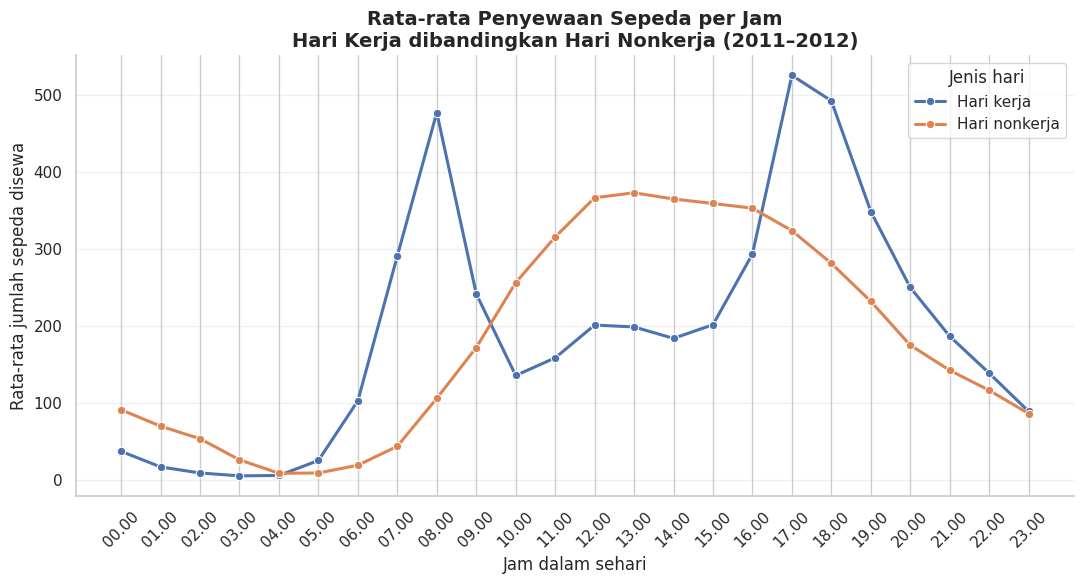

In [ ]:
# Visualisasi Pertanyaan 1: rata-rata penyewaan per jam pada hari kerja dan nonkerja.
fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=hourly_pattern,
    x="hr",
    y="rata_rata_penyewaan",
    hue="workingday_label",
    hue_order=["Hari kerja", "Hari nonkerja"],
    marker="o",
    linewidth=2.2,
    ax=ax
)

ax.set_title(
    "Rata-rata Penyewaan Sepeda per Jam\nHari Kerja dibandingkan Hari Nonkerja (2011–2012)",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata jumlah sepeda disewa")
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f"{hour:02d}.00" for hour in range(24)], rotation=45)
ax.legend(title="Jenis hari")
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pola penyewaan berdasarkan kondisi cuaca

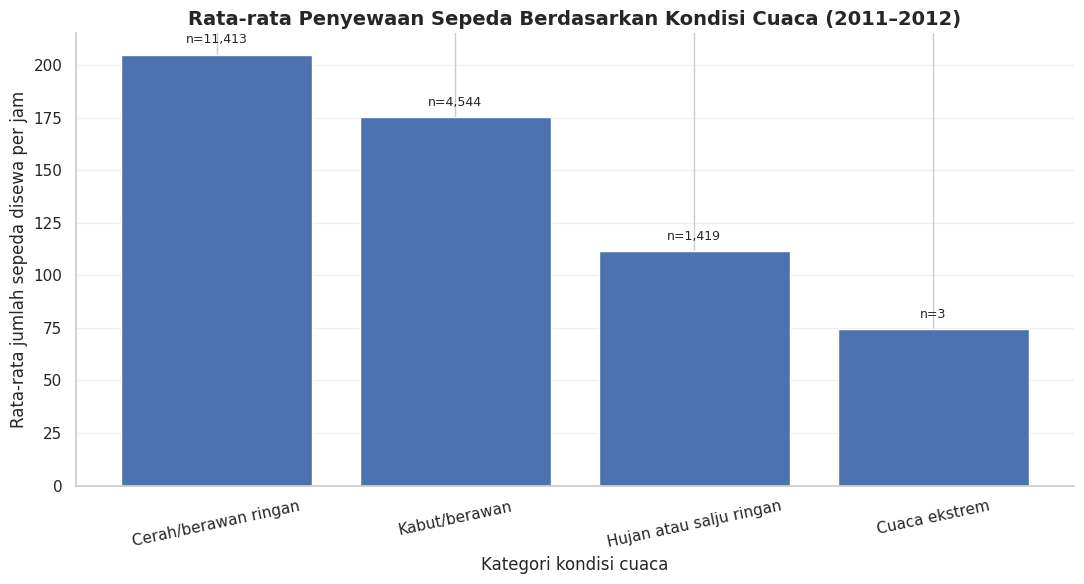

In [ ]:
# Visualisasi Pertanyaan 2: rata-rata penyewaan menurut kondisi cuaca.
weather_plot = (
    weather_summary.set_index("weather_label")
                   .reindex(weather_order)
                   .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(
    weather_plot["weather_label"],
    weather_plot["rata_rata_penyewaan"]
)

# Tampilkan jumlah observasi agar kategori dengan sampel kecil terlihat jelas.
for bar, observations in zip(bars, weather_plot["jumlah_pengamatan"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 4,
        f"n={int(observations):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca (2011–2012)",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Kategori kondisi cuaca")
ax.set_ylabel("Rata-rata jumlah sepeda disewa per jam")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pada hari kerja, rata-rata penyewaan tertinggi terjadi pukul 17.00 (sekitar 525 sepeda per jam), sedangkan hari nonkerja mencapai puncak pukul 13.00 (sekitar 373 sepeda per jam).
- Rata-rata penyewaan tertinggi berdasarkan kondisi cuaca terdapat pada kategori cerah/berawan ringan (sekitar 205), sedangkan cuaca ekstrem sekitar 74 dengan hanya 3 observasi. Karena jumlah observasi kategori terakhir sangat sedikit, hasilnya tidak boleh digeneralisasi.

## Analisis Lanjutan (Opsional)

Rata-rata penyewaan berdasarkan periode waktu:


,workingday_label,period_day,rata_rata_penyewaan,jumlah_pengamatan
0,Hari kerja,Dini hari (00–05),16.44,2912
1,Hari kerja,Pagi (06–10),249.40,2480
2,Hari kerja,Siang (11–15),188.50,2487
3,Hari kerja,Sore (16–18),436.84,1496
4,Hari kerja,Malam (19–23),202.30,2490
5,Hari nonkerja,Dini hari (00–05),43.00,1364
6,Hari nonkerja,Pagi (06–10),119.24,1153
7,Hari nonkerja,Siang (11–15),355.55,1155
8,Hari nonkerja,Sore (16–18),319.17,692
9,Hari nonkerja,Malam (19–23),150.09,1150


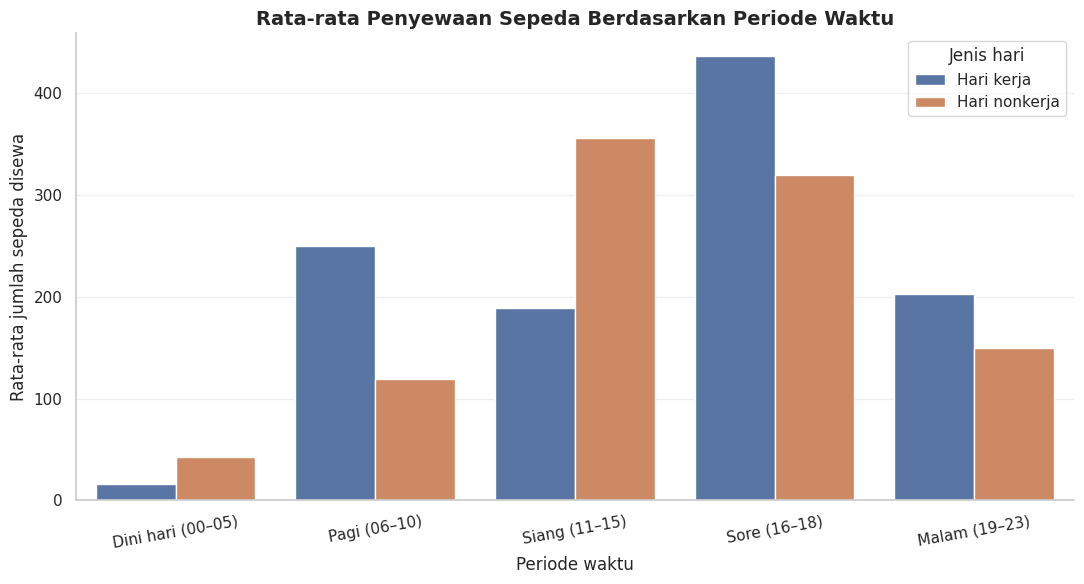

In [ ]:
# Analisis lanjutan: binning jam menjadi periode waktu.
# Pengelompokan ini membantu merangkum kebutuhan operasional per periode.
time_bins = [-1, 5, 10, 15, 18, 23]
time_labels = [
    "Dini hari (00–05)",
    "Pagi (06–10)",
    "Siang (11–15)",
    "Sore (16–18)",
    "Malam (19–23)"
]

df["period_day"] = pd.cut(
    df["hr"],
    bins=time_bins,
    labels=time_labels,
    include_lowest=True
)

period_summary = (
    df.groupby(["workingday_label", "period_day"], observed=False)
      .agg(
          rata_rata_penyewaan=("cnt", "mean"),
          jumlah_pengamatan=("cnt", "size")
      )
      .reset_index()
)

print("Rata-rata penyewaan berdasarkan periode waktu:")
display(period_summary)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=period_summary,
    x="period_day",
    y="rata_rata_penyewaan",
    hue="workingday_label",
    hue_order=["Hari kerja", "Hari nonkerja"],
    ax=ax
)
ax.set_title(
    "Rata-rata Penyewaan Sepeda Berdasarkan Periode Waktu",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Periode waktu")
ax.set_ylabel("Rata-rata jumlah sepeda disewa")
ax.tick_params(axis="x", rotation=10)
ax.legend(title="Jenis hari")
ax.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pengelompokan jam ke dalam periode waktu memperjelas bahwa sore hari merupakan periode dengan rata-rata penyewaan tertinggi pada hari kerja, sedangkan siang hari paling tinggi pada hari nonkerja.
- Hasil pengelompokan ini dapat digunakan sebagai ringkasan operasional, tetapi tidak menggantikan pemeriksaan pola per jam.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama 2011–2012, rata-rata penyewaan pada hari kerja mencapai puncak pukul 17.00 sebesar sekitar 525 sepeda per jam, disusul pukul 08.00 sekitar 477 sepeda per jam. Pada hari nonkerja, puncak terjadi pukul 13.00 sekitar 373 sepeda per jam. Pola ini menunjukkan perbedaan waktu permintaan antara aktivitas komuter dan aktivitas pada hari nonkerja.
- **Conclusion pertanyaan 2:** Rata-rata penyewaan tertinggi tercatat pada cuaca cerah/berawan ringan, sekitar 205 sepeda per jam, kemudian kabut/berawan sekitar 175, dan hujan atau salju ringan sekitar 112. Cuaca ekstrem memiliki rata-rata sekitar 74, tetapi hanya didukung 3 observasi sehingga hasilnya tidak dapat digeneralisasi.

**Rekomendasi Action Item:**
- Menyiapkan ketersediaan sepeda dan petugas redistribusi lebih besar pada hari kerja menjelang pukul 07.00–09.00 dan 16.00–18.00, terutama untuk mengantisipasi puncak sore.
- Pada hari nonkerja, memprioritaskan pemantauan ketersediaan sepeda menjelang siang hingga awal sore, khususnya pukul 11.00–14.00.
- Menggunakan informasi prakiraan cuaca sebagai salah satu masukan perencanaan operasional. Karena observasi cuaca ekstrem hanya 3 catatan, keputusan operasional untuk kondisi tersebut perlu didukung pemantauan tambahan, bukan hanya rata-rata pada dataset ini.